## Student Performance Indicator


#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

### 2.1 Import Data and Required Packages
####  Importing Pandas, Numpy, Matplotlib, Seaborn and Warings Library.

In [1]:
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

#### Import the CSV Data as Pandas DataFrame

In [2]:
df = pl.read_csv('data/stud.csv')

#### Show Top 5 Records

In [3]:
df.head()

gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
str,str,str,str,str,i64,i64,i64
"""female""","""group B""","""bachelor's degree""","""standard""","""none""",72,72,74
"""female""","""group C""","""some college""","""standard""","""completed""",69,90,88
"""female""","""group B""","""master's degree""","""standard""","""none""",90,95,93
"""male""","""group A""","""associate's degree""","""free/reduced""","""none""",47,57,44
"""male""","""group C""","""some college""","""standard""","""none""",76,78,75


#### Shape of the dataset

In [4]:
df.shape

(1000, 8)

### 2.2 Dataset information

- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced) 
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

### 3. Data Checks to perform

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

### 3.1 Check Missing values

In [5]:
df.null_count()

gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0


#### There are no missing values in the data set

In [6]:
df.is_duplicated().sum()

0

#### There are no duplicates  values in the data set

### 3.3 Check data types

you get the datatype of polars dataframe with `head()`, so `glimpse()` might not be required.

In [7]:
df.glimpse(max_items_per_column=3)

Rows: 1000
Columns: 8
$ gender                      <str> 'female', 'female', 'female'
$ race_ethnicity              <str> 'group B', 'group C', 'group B'
$ parental_level_of_education <str> "bachelor's degree", 'some college', "master's degree"
$ lunch                       <str> 'standard', 'standard', 'standard'
$ test_preparation_course     <str> 'none', 'completed', 'none'
$ math_score                  <i64> 72, 69, 90
$ reading_score               <i64> 72, 90, 95
$ writing_score               <i64> 74, 88, 93



### 3.4 Checking the number of unique values of each column

In [8]:
df.select(pl.all().n_unique())

gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
u32,u32,u32,u32,u32,u32,u32,u32
2,5,6,2,2,81,72,77


### 3.5 Check statistics of data set

In [9]:
df.describe()

statistic,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
str,str,str,str,str,str,f64,f64,f64
"""count""","""1000""","""1000""","""1000""","""1000""","""1000""",1000.0,1000.0,1000.0
"""null_count""","""0""","""0""","""0""","""0""","""0""",0.0,0.0,0.0
"""mean""",null,null,null,null,null,66.089,69.169,68.054
"""std""",null,null,null,null,null,15.16308,14.600192,15.195657
"""min""","""female""","""group A""","""associate's degree""","""free/reduced""","""completed""",0.0,17.0,10.0
"""25%""",null,null,null,null,null,57.0,59.0,58.0
"""50%""",null,null,null,null,null,66.0,70.0,69.0
"""75%""",null,null,null,null,null,77.0,79.0,79.0
"""max""","""male""","""group E""","""some high school""","""standard""","""none""",100.0,100.0,100.0


#### Insight
- From above description of numerical data, all means are very close to each other - between 66 and 68.05;
- All standard deviations are also close - between 14.6 and 15.19;
- While there is a minimum score  0 for math, for writing minimum is much higher = 10 and for reading myet higher = 17

### 3.7 Exploring Data

In [10]:
str_col = df.select(cs.string()).columns
max_len = max(len(col) for col in str_col)

for col in str_col:
   # print(f'unique values in {col: <{max_len}}: {list(df[col].unique().sort())}') # same row alignment
    print(f'unique values in {col}: \n{list(df[col].unique().sort())}\n')

unique values in gender: 
['female', 'male']

unique values in race_ethnicity: 
['group A', 'group B', 'group C', 'group D', 'group E']

unique values in parental_level_of_education: 
["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']

unique values in lunch: 
['free/reduced', 'standard']

unique values in test_preparation_course: 
['completed', 'none']



In [11]:
# define numerical & categorical columns
numeric_features = df.select(cs.numeric()).columns
categorical_features = str_col

print(f'numeric features: \n{numeric_features}\n')
print(f'categorical features: \n{categorical_features}\n')

numeric features: 
['math_score', 'reading_score', 'writing_score']

categorical features: 
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']



### 3.8 Adding columns for "Total Score" and "Average"

In [12]:
df = df.with_columns(total_score = pl.sum_horizontal(pl.col(numeric_features)))
df = df.with_columns(average = pl.col('total_score') / 3)
df.head()

gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
str,str,str,str,str,i64,i64,i64,i64,f64
"""female""","""group B""","""bachelor's degree""","""standard""","""none""",72,72,74,218,72.666667
"""female""","""group C""","""some college""","""standard""","""completed""",69,90,88,247,82.333333
"""female""","""group B""","""master's degree""","""standard""","""none""",90,95,93,278,92.666667
"""male""","""group A""","""associate's degree""","""free/reduced""","""none""",47,57,44,148,49.333333
"""male""","""group C""","""some college""","""standard""","""none""",76,78,75,229,76.333333


In [13]:
df.select([
    (pl.col(nf) == 100).sum().alias(f'{nf}_count_100')
    for nf in numeric_features
])

math_score_count_100,reading_score_count_100,writing_score_count_100
u32,u32,u32
7,17,14


In [14]:
df.select([
    (pl.col(nf) <= 20).sum().alias(f'{nf}_count_less_20')
    for nf in numeric_features
])

math_score_count_less_20,reading_score_count_less_20,writing_score_count_less_20
u32,u32,u32
4,1,3


#####  Insights
 - From above values we get students have performed the worst in Maths 
 - Best performance is in reading section

### 4. Exploring Data ( Visualization )
#### 4.1 Visualize average score distribution to make some conclusion. 
- Histogram
- Kernel Distribution Function (KDE)

#### 4.1.1 Histogram & KDE

In [15]:
# convert polars df to pandas to allow plotting
df_plot = df.to_pandas()

<Axes: xlabel='average', ylabel='Count'>

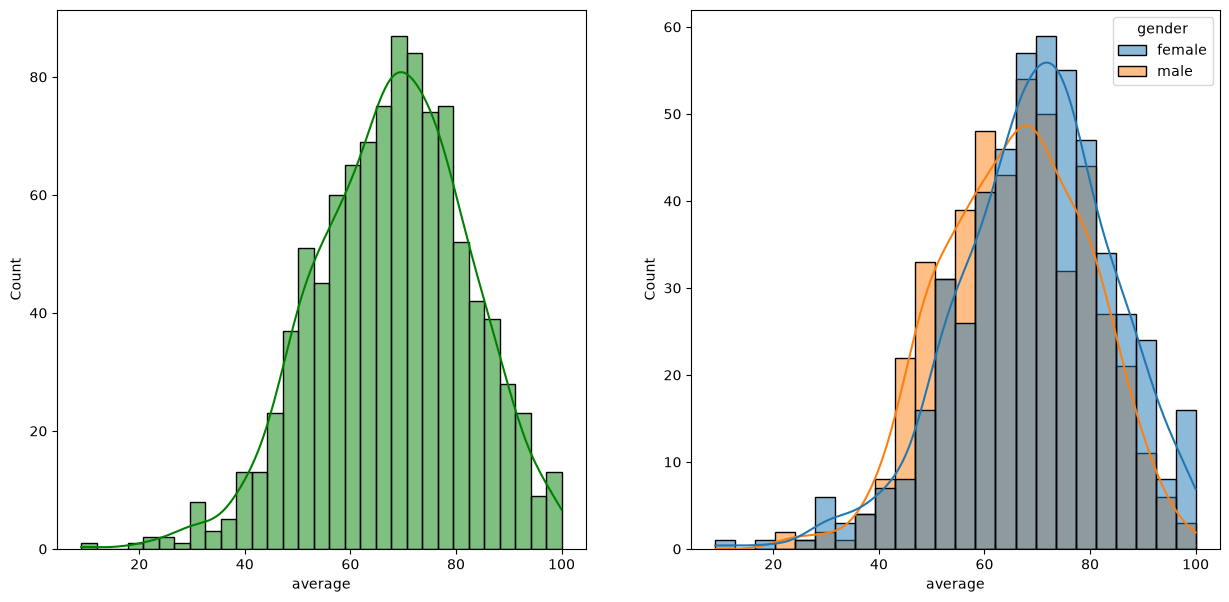

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df_plot, x='average', bins=31, kde=True, color='g')
plt.subplot(122)
sns.histplot(data=df_plot, x='average', kde=True, hue='gender')

<Axes: xlabel='total_score', ylabel='Count'>

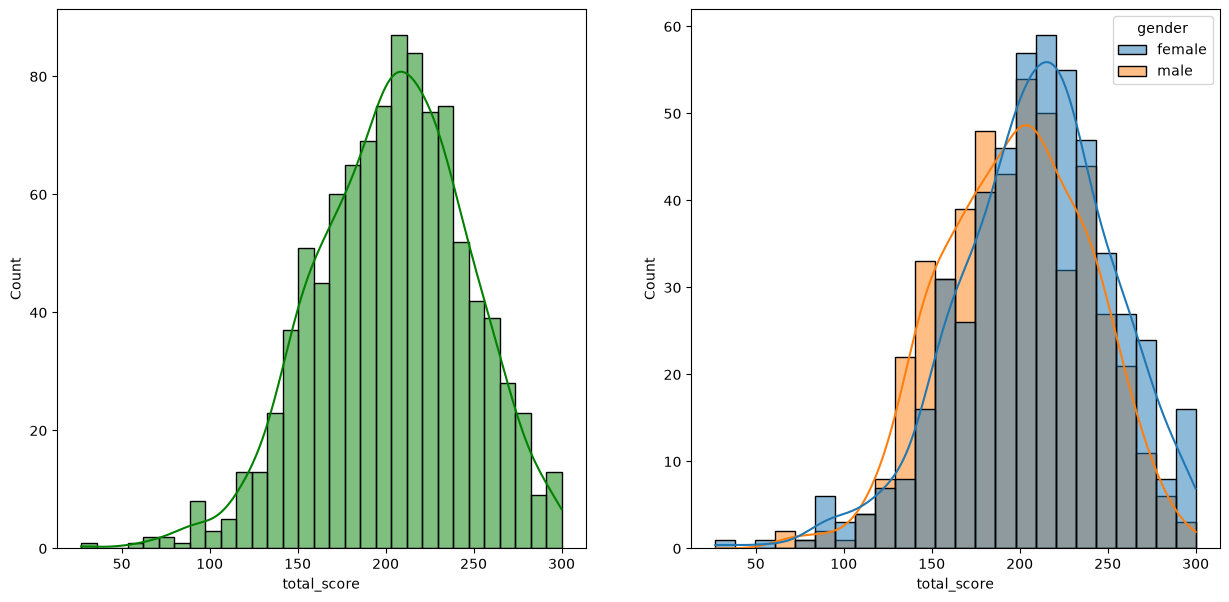

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df_plot, x='total_score', bins=31, kde=True, color='g')
plt.subplot(122)
sns.histplot(data=df_plot, x='total_score', kde=True, hue='gender')

#####  Insights
- Female students tend to perform well then male students.

Text(0.5, 1.0, 'Male')

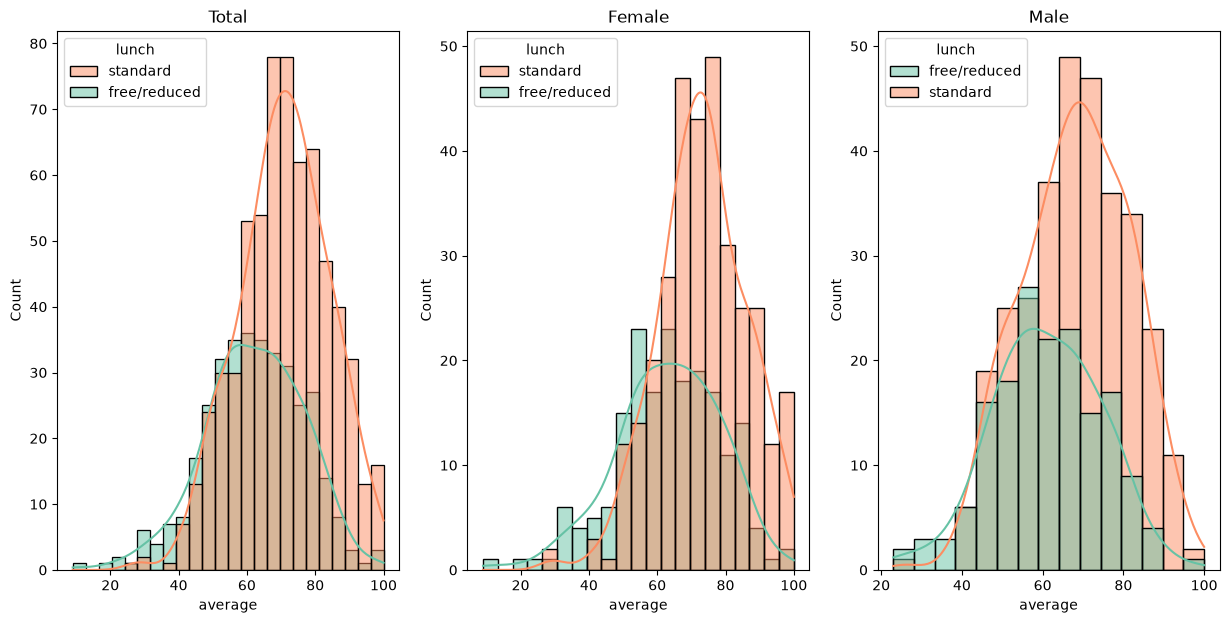

In [18]:
hue_order = sorted(df_plot['lunch'].unique())
colors = sns.color_palette('Set2', len(hue_order))
palette = dict(zip(hue_order, colors))

fig, axs = plt.subplots(1, 3, figsize=(15, 7))
plt.subplot(131)
sns.histplot(data=df_plot, x='average', kde=True, hue='lunch', palette=palette).set_title('Total')
plt.subplot(132)
sns.histplot(data=df_plot[df_plot.gender == 'female'], x='average', kde=True, hue='lunch', palette=palette).set_title('Female')
plt.subplot(133)
sns.histplot(data=df_plot[df_plot.gender == 'male'], x='average', kde=True, hue='lunch', palette=palette).set_title('Male')

#####  Insights
- Standard lunch helps perform well in exams.
- Standard lunch helps perform well in exams be it a male or a female.

Text(0.5, 1.0, 'Male')

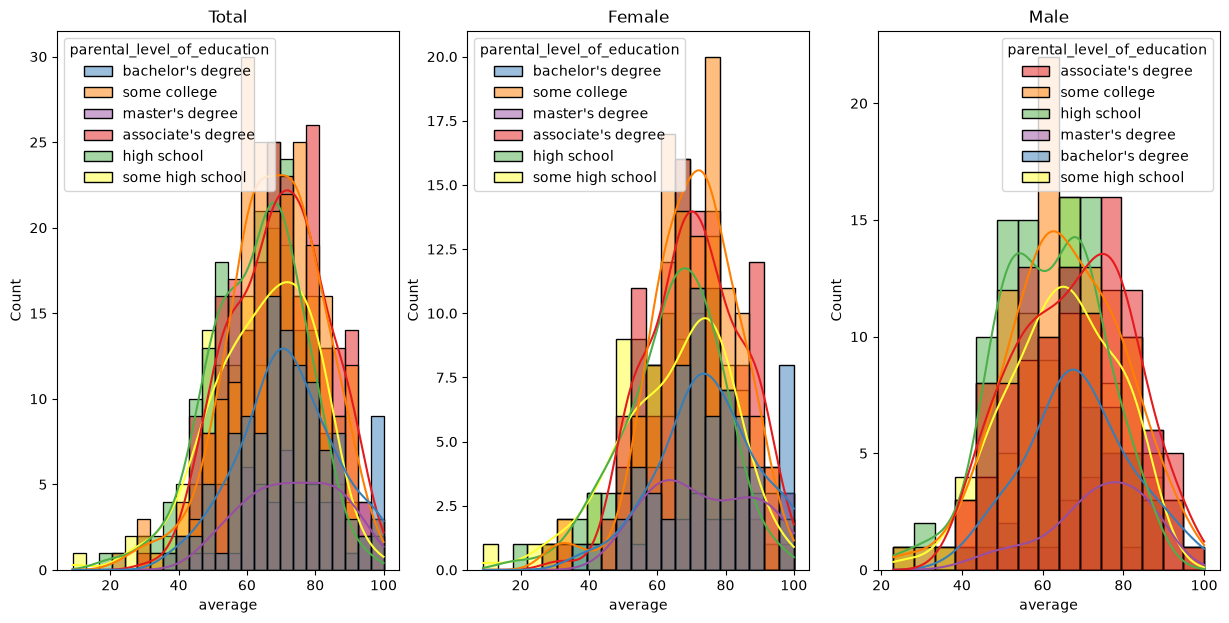

In [19]:
hue_order = sorted(df_plot['parental_level_of_education'].unique())
colors = sns.color_palette('Set1', len(hue_order))
palette = dict(zip(hue_order, colors))

fig, axs = plt.subplots(1, 3, figsize=(15, 7))
plt.subplot(131)
sns.histplot(data=df_plot, x='average', kde=True, hue='parental_level_of_education', palette=palette).set_title('Total')
plt.subplot(132)
sns.histplot(data=df_plot[df_plot.gender == 'female'], x='average', kde=True, hue='parental_level_of_education', palette=palette).set_title('Female')
plt.subplot(133)
sns.histplot(data=df_plot[df_plot.gender == 'male'], x='average', kde=True, hue='parental_level_of_education', palette=palette).set_title('Male')

#####  Insights
- In general parent's education don't help student perform well in exam.
- 2nd plot we can see there is no effect of parent's education on female students.
- 3rd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam

Text(0.5, 1.0, 'Male')

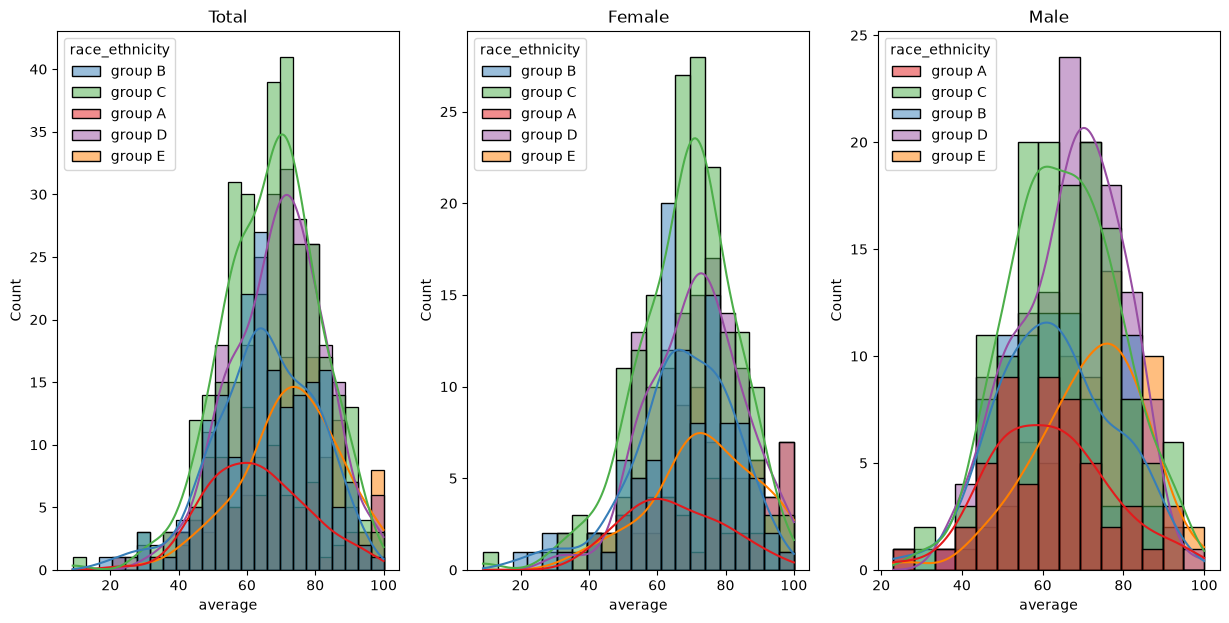

In [20]:
hue_order = sorted(df_plot['race_ethnicity'].unique())
colors = sns.color_palette('Set1', len(hue_order))
palette = dict(zip(hue_order, colors))

fig, axs = plt.subplots(1, 3, figsize=(15, 7))
plt.subplot(131)
sns.histplot(data=df_plot, x='average', kde=True, hue='race_ethnicity', palette=palette).set_title('Total')
plt.subplot(132)
sns.histplot(data=df_plot[df_plot.gender == 'female'], x='average', kde=True, hue='race_ethnicity', palette=palette).set_title('Female')
plt.subplot(133)
sns.histplot(data=df_plot[df_plot.gender == 'male'], x='average', kde=True, hue='race_ethnicity', palette=palette).set_title('Male')

#####  Insights
- Students of group C and group D tends to perform better than others.
- Students of group C perform better than group D if they are female, but not much difference if male
- Students of group A and group B tends to perform poorly in exam.
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female

#### 4.2 Maximumum score of students in all three subjects

<Axes: ylabel='writing_score'>

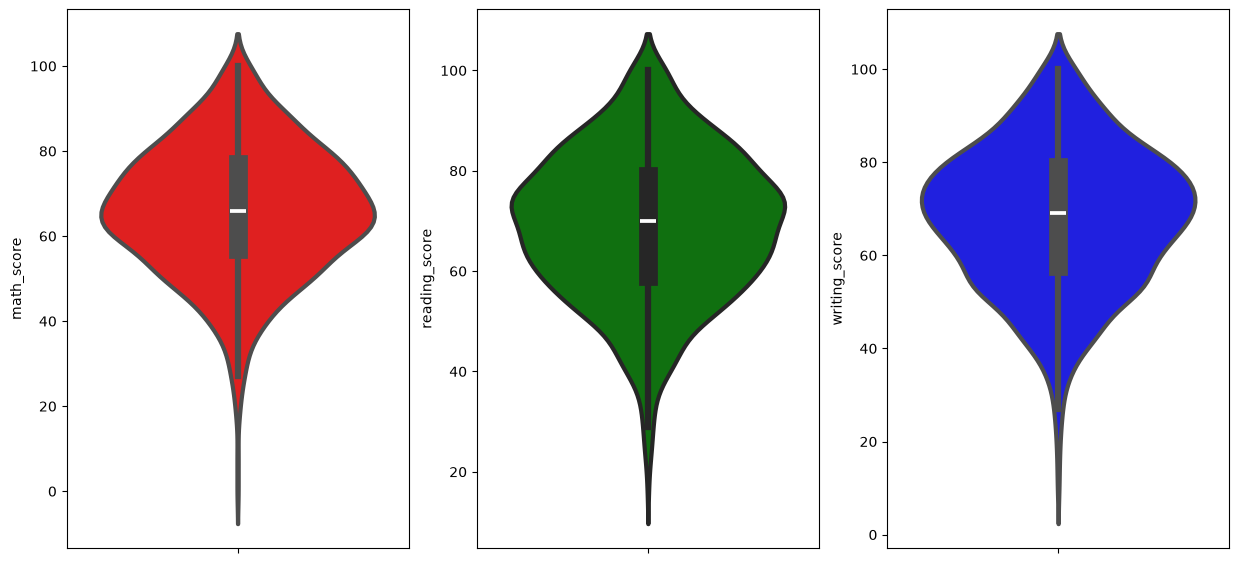

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15, 7))
plt.subplot(131)
sns.violinplot(y='math_score', data=df_plot, color='red', linewidth=3)
plt.subplot(132)
sns.violinplot(y='reading_score', data=df_plot, color='green', linewidth=3)
plt.subplot(133)
sns.violinplot(y='writing_score', data=df_plot, color='blue', linewidth=3)

#### Insights
- From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80

#### 4.3 Multivariate analysis using pieplot

In [22]:
def pie_plot(feature, index):
    colors = ['red', 'green', 'blue', 'orange', 'yellow', 'aqua']

    plt.subplot(1, 5, index)
    size = df_plot[feature].value_counts()
    labels = size.index
    color = colors[:len(labels)]

    plt.pie(size, colors=color, labels=labels, autopct='.%2f%%')
    plt.title(feature.title().replace('_', ' '), fontsize=20)
    plt.axis('off')

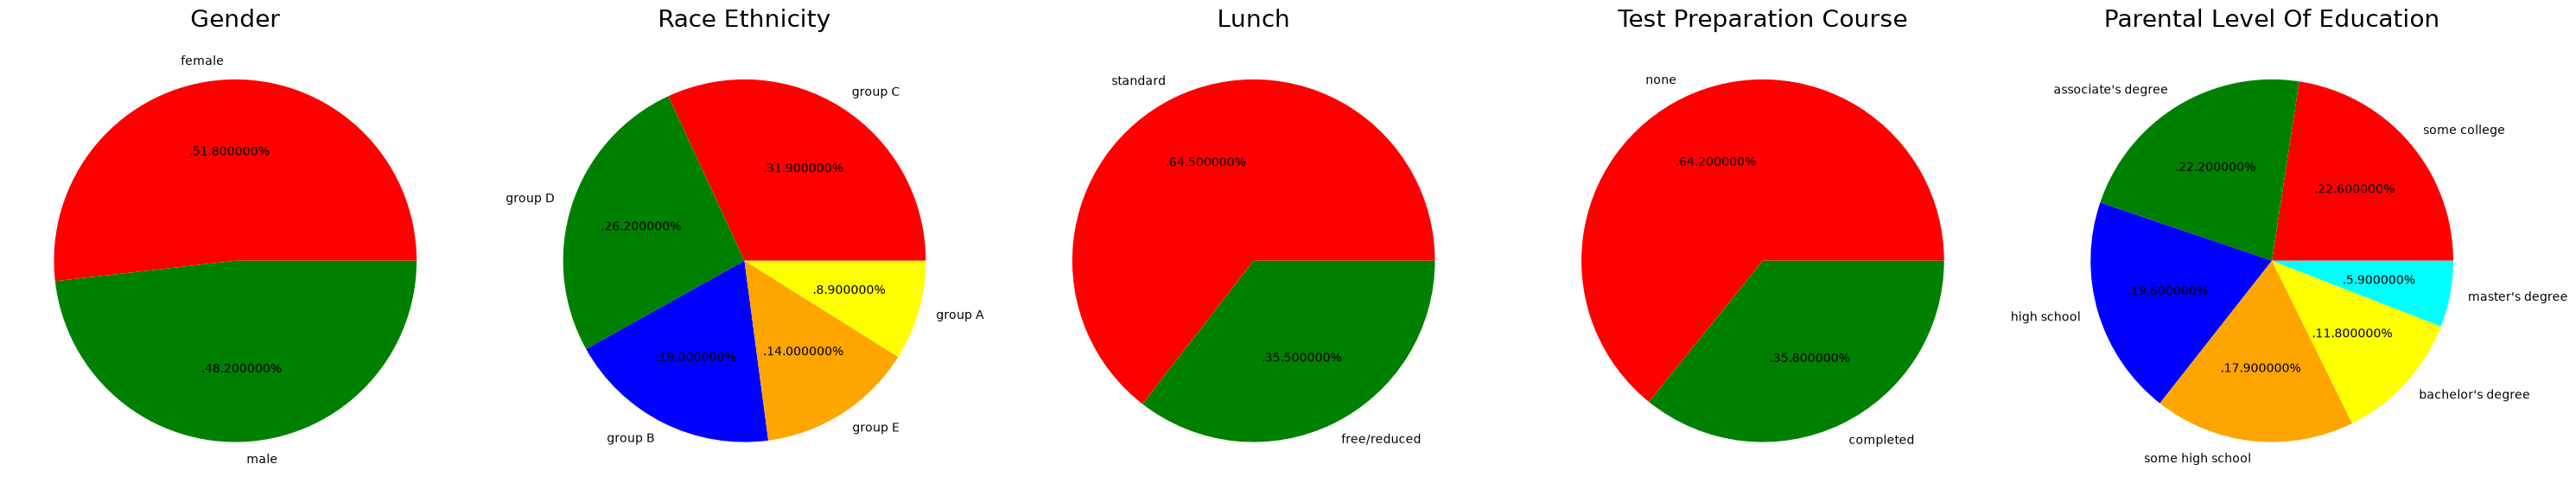

In [23]:
plt.rcParams['figure.figsize'] = (30, 15)

pie_plot('gender', 1)

pie_plot('race_ethnicity', 2)

pie_plot('lunch', 3)

pie_plot('test_preparation_course', 4)

pie_plot('parental_level_of_education', 5)

plt.tight_layout()
plt.grid()

#####  Insights
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are 2/3 of dataset
- Number of students who have not enrolled in any test preparation course are 2/3 of dataset
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

#### 4.4 Feature Wise Visualization
#### 4.4.1 GENDER COLUMN
- How is distribution of Gender ?
- Is gender has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is distribution of Gender ? )

Same as above pie plot

#### BIVARIATE ANALYSIS ( Is gender has any impact on student's performance ? ) 

In [24]:
gender_group = df_plot.groupby('gender').mean(numeric_only=True)
gender_group

,math_score,reading_score,writing_score,total_score,average
gender,,,,,
female,63.633205,72.608108,72.467181,208.708494,69.569498
male,68.728216,65.473029,63.311203,197.512448,65.837483


<Axes: xlabel='gender'>

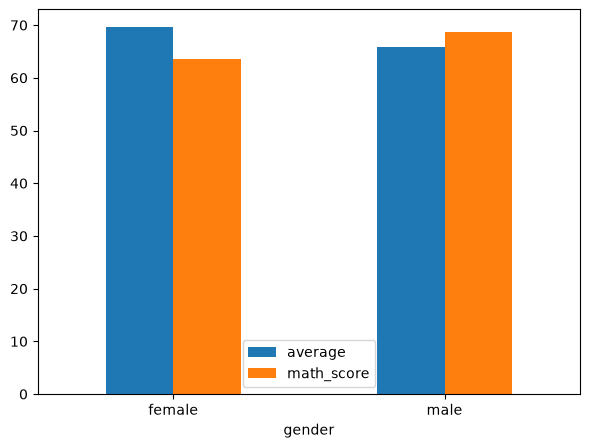

In [25]:
gender_group.loc[:, ['average', 'math_score']].plot(kind='bar', figsize=(7, 5), rot=0)

#### Insights 
- On an average females have a better overall score than men.
- whereas males have scored higher in Maths.

#### 4.4.2 RACE/EHNICITY COLUMN
- How is Group wise distribution ?
- Is Race/Ehnicity has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( How is Group wise distribution ?)

same as pie chart

#### BIVARIATE ANALYSIS ( Is Race/Ehnicity has any impact on student's performance ? )

In [26]:
race_ethnicity_group = df_plot.groupby('race_ethnicity').mean(numeric_only=True)
race_ethnicity_group

,math_score,reading_score,writing_score,total_score,average
race_ethnicity,,,,,
group A,61.629213,64.674157,62.674157,188.977528,62.992509
group B,63.452632,67.352632,65.600000,196.405263,65.468421
group C,64.463950,69.103448,67.827586,201.394984,67.131661
group D,67.362595,70.030534,70.145038,207.538168,69.179389
group E,73.821429,73.028571,71.407143,218.257143,72.752381


<Axes: xlabel='race_ethnicity'>

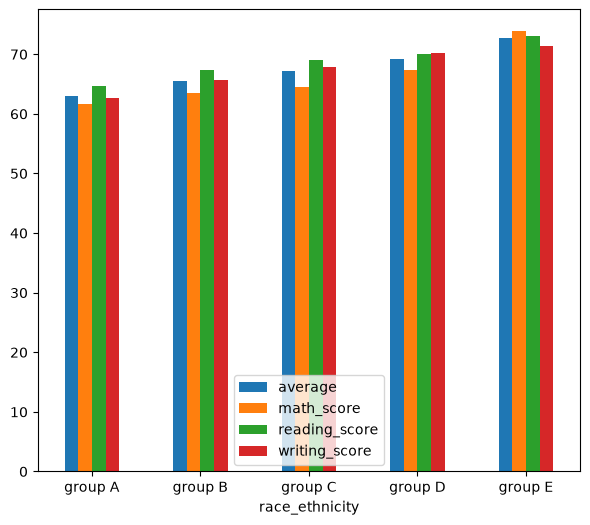

In [27]:
race_ethnicity_group.\
    loc[:, ['average', 'math_score', 'reading_score', 'writing_score']].\
    plot(kind='bar', figsize=(7, 6), rot=0)

#### Insights
- Group E students have scored the highest marks.
- Group A students have scored the lowest marks.

#### 4.4.3 PARENTAL LEVEL OF EDUCATION COLUMN
- What is educational background of student's parent ?
- Is parental education has any impact on student's performance ?

#### UNIVARIATE ANALYSIS ( What is educational background of student's parent ? )

same as pie chart

#### BIVARIATE ANALYSIS ( Is parental education has any impact on student's performance ? )

<Axes: ylabel='parental_level_of_education'>

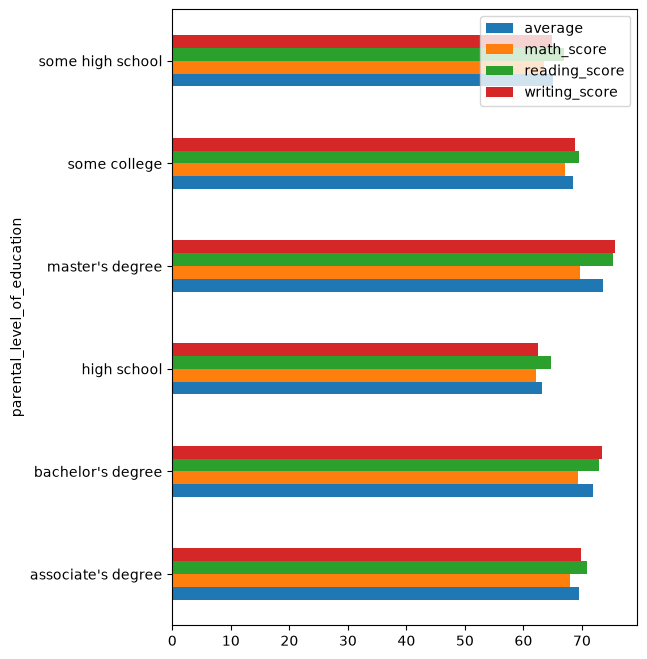

In [28]:
df_plot.\
    groupby('parental_level_of_education').\
    mean(numeric_only=True).\
    loc[:, ['average', 'math_score', 'reading_score', 'writing_score']].\
    plot(kind='barh', figsize=(6, 8), rot=0)

#### Insights 
- The score of student whose parents possess master and bachelor level education are higher than others.

#### 4.4.4 LUNCH COLUMN 
- Which type of lunch is most common amoung students ?
- What is the effect of lunch type on test results?


#### UNIVARIATE ANALYSIS ( Which type of lunch is most common amoung students ? )

same as pie chart

#### BIVARIATE ANALYSIS (  Is lunch type intake has any impact on student's performance ? )

<Axes: ylabel='lunch'>

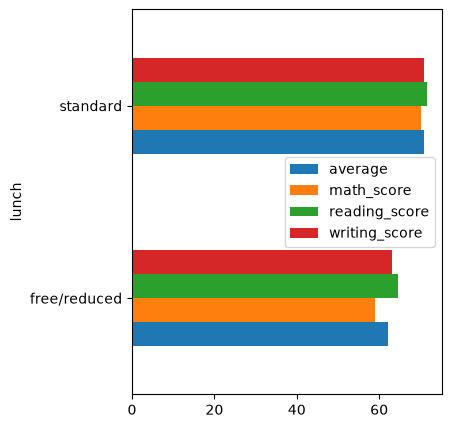

In [29]:
df_plot.\
    groupby('lunch').\
    mean(numeric_only=True).\
    loc[:, ['average', 'math_score', 'reading_score', 'writing_score']].\
    plot(kind='barh', figsize=(4, 5), rot=0)

#### Insights 
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch

#### 4.4.5 TEST PREPARATION COURSE COLUMN 
- Which type of lunch is most common amoung students ?
- Is Test prepration course has any impact on student's performance ?

#### BIVARIATE ANALYSIS ( Is Test prepration course has any impact on student's performance ? )

<Axes: ylabel='test_preparation_course'>

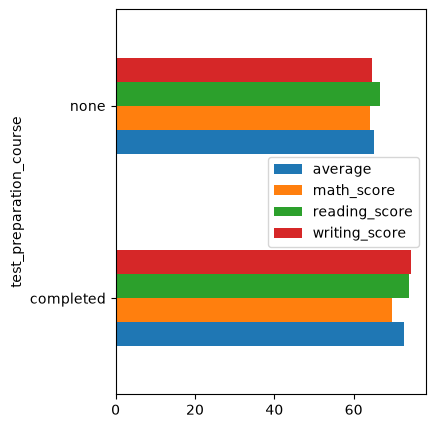

In [30]:
df_plot.\
    groupby('test_preparation_course').\
    mean(numeric_only=True).\
    loc[:, ['average', 'math_score', 'reading_score', 'writing_score']].\
    plot(kind='barh', figsize=(4, 5), rot=0)

#### Insights  
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course

#### 4.4.6 CHECKING OUTLIERS

Text(0.5, 1.0, 'Average')

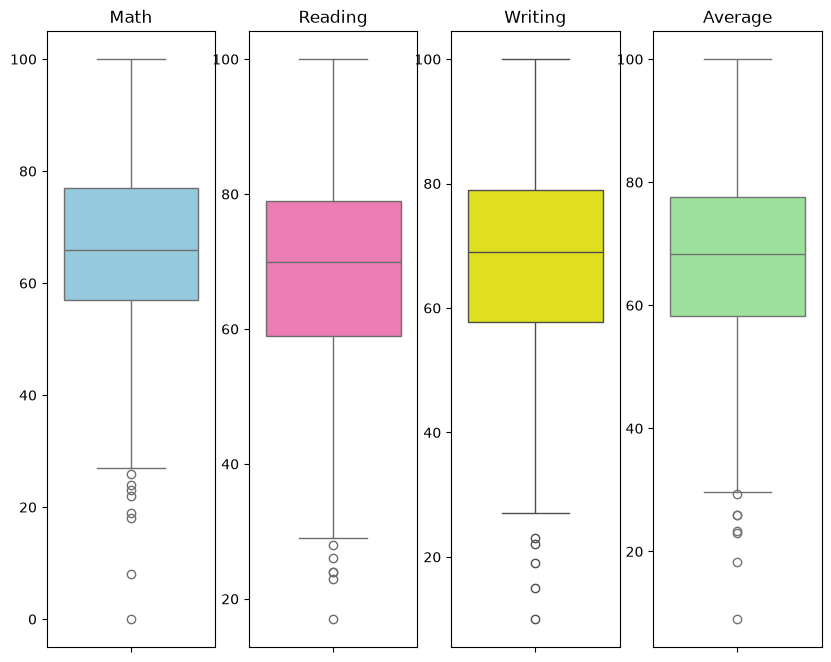

In [31]:
plt.subplots(1, 4, figsize=(10, 8))
plt.subplot(141)
sns.boxplot(df['math_score'], color='skyblue').set_title('Math')
plt.subplot(142)
sns.boxplot(df['reading_score'], color='hotpink').set_title('Reading')
plt.subplot(143)
sns.boxplot(df['writing_score'], color='yellow').set_title('Writing')
plt.subplot(144)
sns.boxplot(df['average'], color='lightgreen').set_title('Average')

#### 4.4.7 MUTIVARIATE ANALYSIS USING PAIRPLOT

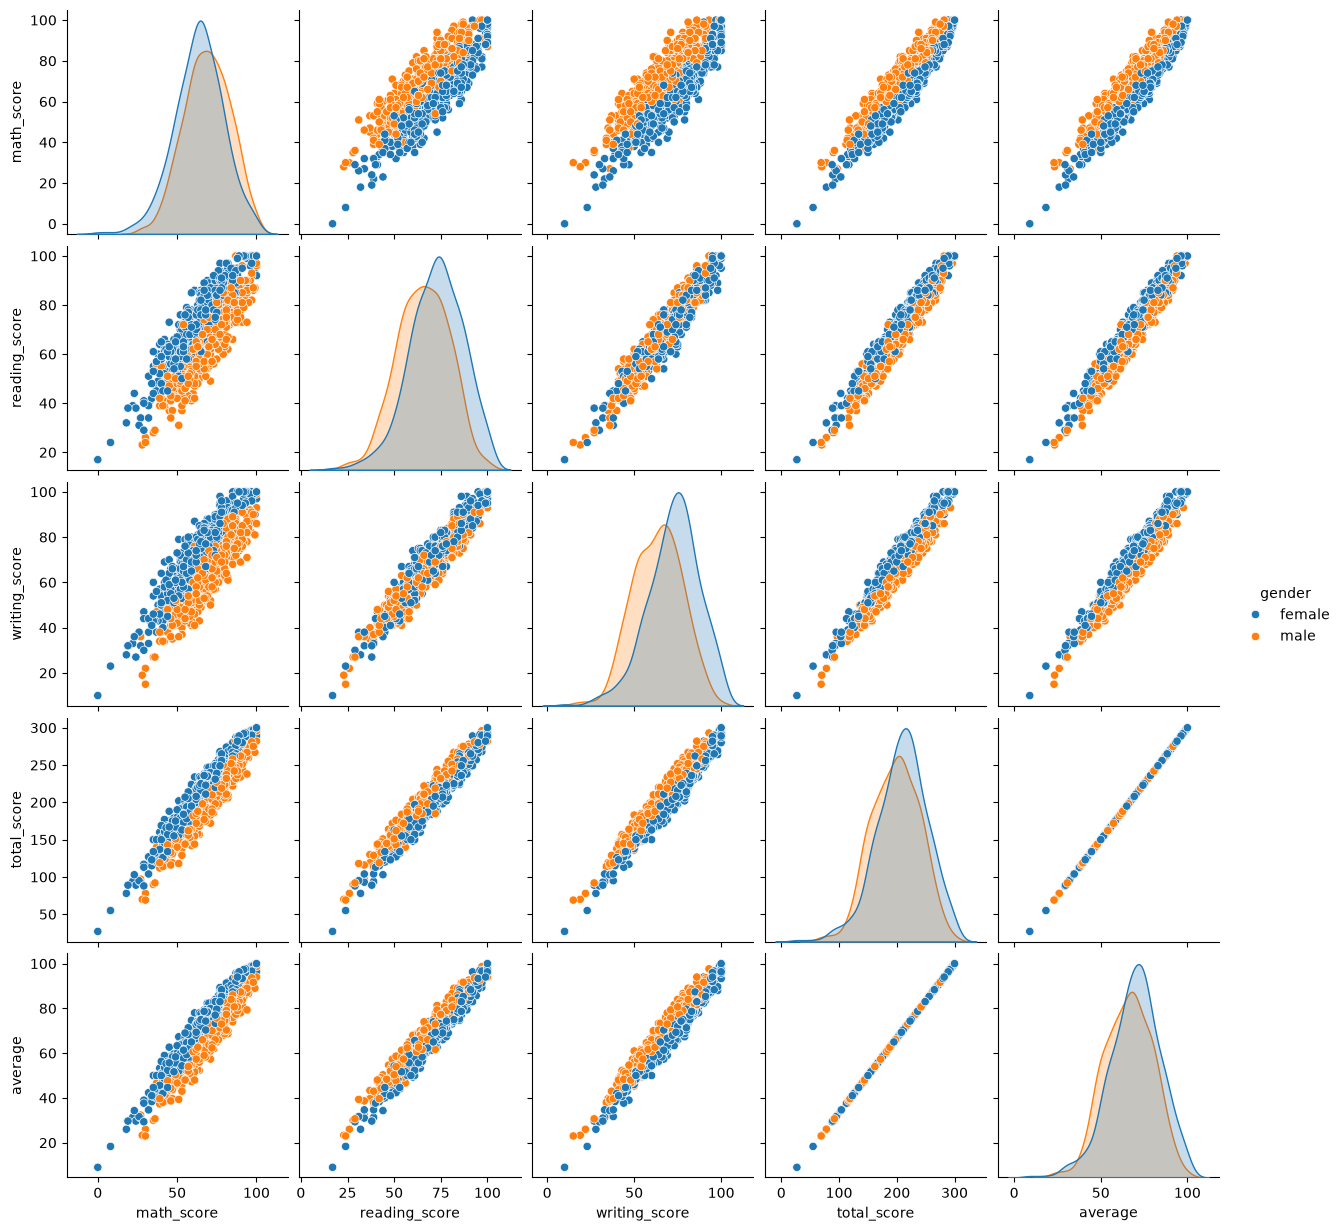

In [32]:
sns.pairplot(df_plot, hue='gender')

#### Insights
- From the above plot it is clear that all the scores increase linearly with each other.

### 5. Conclusions
- Student's Performance is related with lunch, race, parental level education
- Females lead in pass percentage and also are top-scorers
- Student's Performance is not much related with test preparation course
- Finishing preparation course is benefitial.